# Week 1 — EDA + Visualisations
**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository (569 tumour samples, 30 numeric features computed from digitised images of a fine-needle aspirate).
**Goal:** understand the data *before* modelling — clean it, explore relationships with 5 visualisations, and note takeaways that will shape the model in Weeks 2–4.

Target used throughout this project: `malignant` (1 = malignant, 0 = benign), so "positive" means the dangerous class.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")

df = pd.read_csv("../data/breast_cancer_wisconsin.csv")
df.shape

(569, 32)

## 1. Cleaning with Pandas

In [2]:
print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print("Dtypes         :", df.dtypes.value_counts().to_dict())
df.head()

Missing values : 0
Duplicate rows : 0
Dtypes         : {dtype('float64'): 30, <StringDtype(storage='python', na_value=nan)>: 1, dtype('int64'): 1}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant,1


In [3]:
# tidy column names: snake_case is easier to work with in code and in the app later
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df["diagnosis"] = df["diagnosis"].astype("category")
df.describe().T[["mean", "std", "min", "50%", "max"]].round(3).head(10)

,mean,std,min,50%,max
mean_radius,14.127,3.524,6.981,13.370,28.110
mean_texture,19.290,4.301,9.710,18.840,39.280
mean_perimeter,91.969,24.299,43.790,86.240,188.500
mean_area,654.889,351.914,143.500,551.100,2501.000
mean_smoothness,0.096,0.014,0.053,0.096,0.163
mean_compactness,0.104,0.053,0.019,0.093,0.345
mean_concavity,0.089,0.080,0.000,0.062,0.427
mean_concave_points,0.049,0.039,0.000,0.034,0.201
mean_symmetry,0.181,0.027,0.106,0.179,0.304
mean_fractal_dimension,0.063,0.007,0.050,0.062,0.097


The data arrives clean (no missing values, no duplicates), so cleaning here means standardising names and types and **checking scale**: features range from ~0.01 (smoothness) to ~2500 (area). Scale-sensitive models will need scaling later.

## 2. Five visualisations

### Viz 1 — Class balance

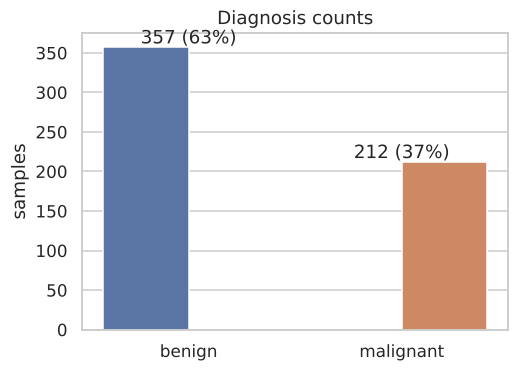

In [4]:
counts = df["diagnosis"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax, hue=counts.index, legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({v/len(df):.0%})", ha="center")
ax.set(title="Diagnosis counts", xlabel="", ylabel="samples")
plt.show()

### Viz 2 — Distributions by class (the best single features)

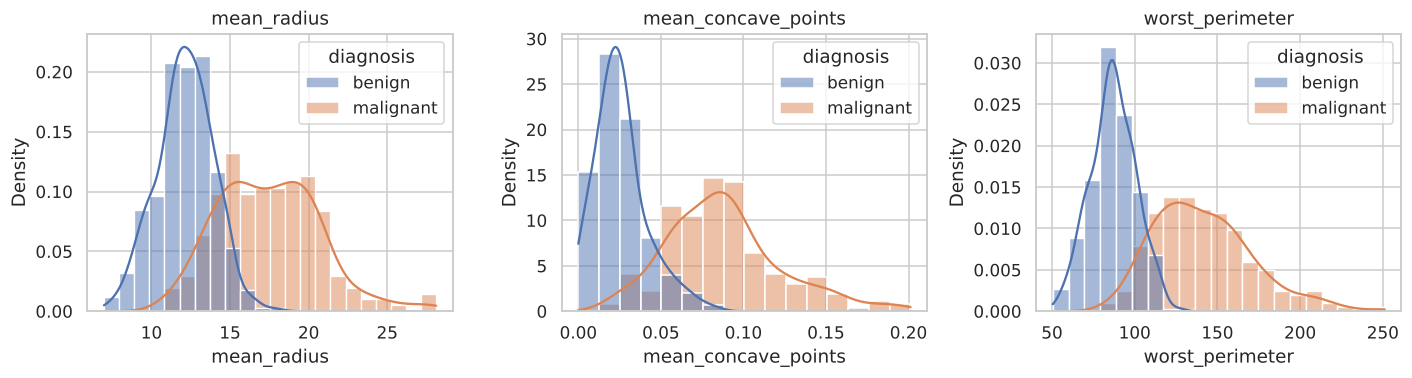

In [5]:
feats = ["mean_radius", "mean_concave_points", "worst_perimeter"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, f in zip(axes, feats):
    sns.histplot(data=df, x=f, hue="diagnosis", kde=True, stat="density", common_norm=False, ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.show()

### Viz 3 — Outliers (boxplots)

{'mean_radius': 14, 'mean_area': 25, 'area_error': 65, 'mean_texture': 7}

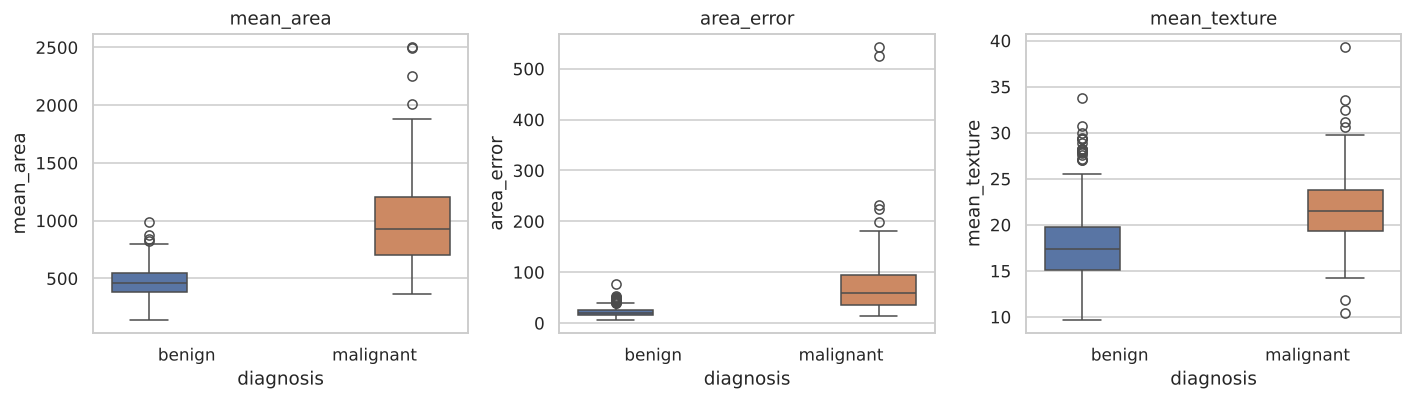

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, f in zip(axes, ["mean_area", "area_error", "mean_texture"]):
    sns.boxplot(data=df, x="diagnosis", y=f, hue="diagnosis", legend=False, ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())
{f: iqr_outliers(df[f]) for f in ["mean_radius", "mean_area", "area_error", "mean_texture"]}

### Viz 4 — Correlation with the target

mean_perimeter          0.743
worst_radius            0.776
mean_concave_points     0.777
worst_perimeter         0.783
worst_concave_points    0.794
Name: malignant, dtype: float64

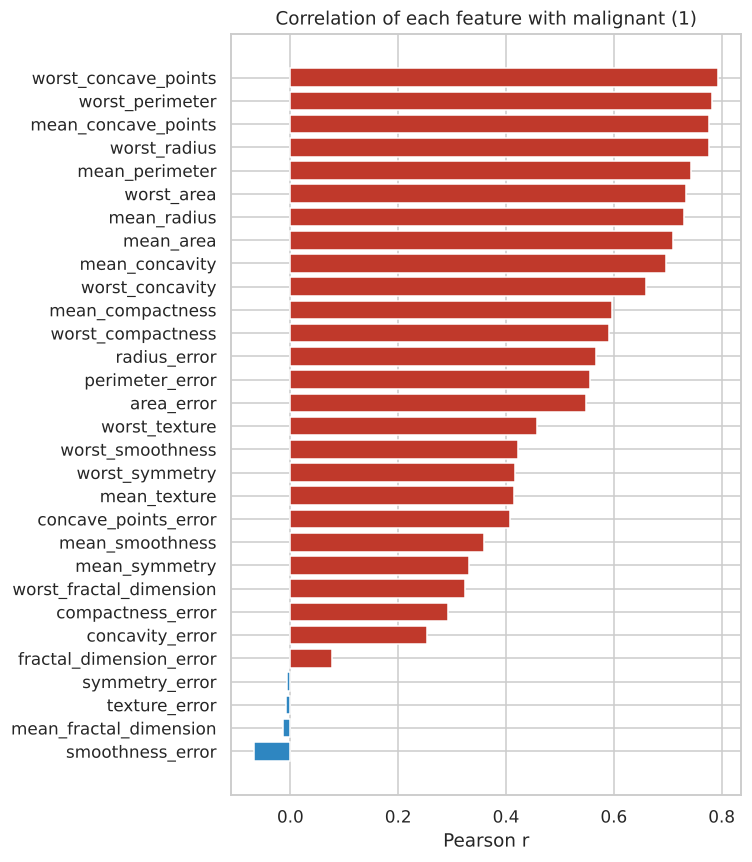

In [7]:
corr_t = df.drop(columns="diagnosis").corr()["malignant"].drop("malignant").sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
colors = ["#c0392b" if v > 0 else "#2e86c1" for v in corr_t.values]
ax.barh(corr_t.index, corr_t.values, color=colors)
ax.set(title="Correlation of each feature with malignant (1)", xlabel="Pearson r")
plt.tight_layout(); plt.show()
corr_t.tail(5).round(3)

### Viz 5 — Feature-vs-feature correlation (multicollinearity)

Feature pairs with |r| > 0.9: 21


mean_radius     mean_perimeter     0.998
worst_radius    worst_perimeter    0.994
mean_radius     mean_area          0.987
mean_perimeter  mean_area          0.987
worst_radius    worst_area         0.984
dtype: float64

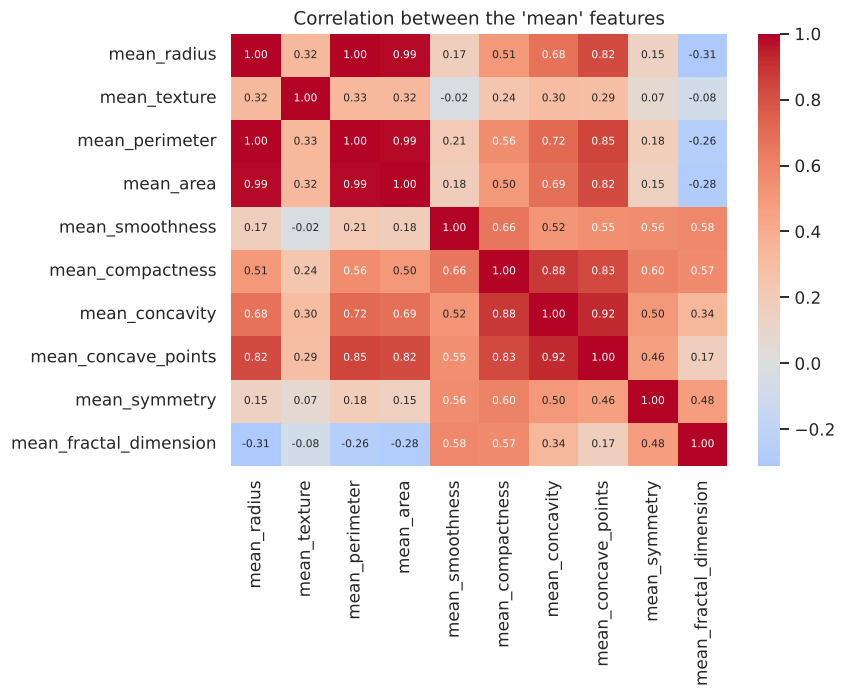

In [8]:
mean_cols = [c for c in df.columns if c.startswith("mean_")]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[mean_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation between the 'mean' features")
plt.tight_layout(); plt.show()

num = df.drop(columns=["diagnosis", "malignant"]).corr().abs()
pairs = num.where(np.triu(np.ones(num.shape), 1).astype(bool)).stack()
print("Feature pairs with |r| > 0.9:", int((pairs > 0.9).sum()))
pairs.sort_values(ascending=False).head(5).round(3)

## 3. Key takeaways

1. **Mild class imbalance.** 357 benign (63%) vs 212 malignant (37%). Plain accuracy would flatter a model that leans towards "benign", so later weeks judge models on precision, recall and F1 for the malignant class.
2. **Size and shape features separate the classes best.** `worst_concave_points` (r ≈ 0.79), `worst_perimeter` (0.78), `mean_concave_points` (0.78) and `worst_radius` (0.78) correlate most strongly with malignancy. On average malignant tumours have a mean radius of 17.5 vs 12.1 for benign.
3. **Outliers are real, not errors.** `area_error` has 65 IQR outliers, `mean_area` 25. These are mostly large malignant tumours, so they are signal, and I keep them rather than dropping rows.
4. **Heavy multicollinearity.** 21 feature pairs have |r| > 0.9 (e.g. radius/perimeter/area ≈ 0.99). Tree models don't mind, but linear models get unstable coefficients — a reason to compare a linear and a tree model.
5. **Wildly different scales** (smoothness ≈ 0.1 vs area ≈ 600+). Scaling is required for logistic regression and any distance-based model; I use a pipeline so scaling is fitted on training data only.

**Implications for modelling:** stratified train/test split, scale inside a pipeline, report recall/precision/F1, keep outliers.